In [12]:
import matplotlib.pyplot as plt

In [2]:
import h2o
import numpy as np
import pandas as pd
import pyodbc
from h2o.estimators import H2OExtendedIsolationForestEstimator, H2ORandomForestEstimator
import warnings
import json
h2o.init(nthreads=-1,enable_assertions=False)
warnings.filterwarnings('ignore')

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
; Java HotSpot(TM) 64-Bit Server VM (build 25.391-b13, mixed mode)
  Starting server from C:\T0001\dse\Python\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: C:\Users\DAN~1.LAR\AppData\Local\Temp\2\tmp3_obwntd
  JVM stdout: C:\Users\DAN~1.LAR\AppData\Local\Temp\2\tmp3_obwntd\h2o_dan_larson_started_from_python.out
  JVM stderr: C:\Users\DAN~1.LAR\AppData\Local\Temp\2\tmp3_obwntd\h2o_dan_larson_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,04 secs
H2O_cluster_timezone:,America/New_York
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.44.0.2
H2O_cluster_version_age:,2 months and 17 days
H2O_cluster_name:,H2O_from_python_dan_larson_8xj2lp
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.477 Gb
H2O_cluster_total_cores:,4
H2O_cluster_allowed_cores:,4
H2O_cluster_status:,"locked, healthy"


In [73]:
import duckdb as db
dat = db.sql("select * from read_parquet('C:\MLAR_DATA\T0001\MLAR_RAW_SERES.parquet')").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [20]:
engineered_features = db.sql("select sample_number, count(*) as audit_count, max(audit_timestamp) as last_audit_date, min(audit_timestamp) as first_audit_date from read_parquet('C:\MLAR_DATA\T0001\MLAR_RAW_SERES.parquet') group by sample_number").to_df()

<Axes: ylabel='Frequency'>

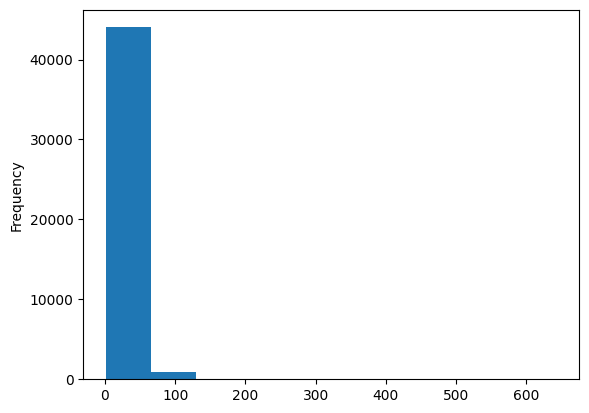

In [13]:
engineered_features['audit_count'].plot(kind='hist')

In [14]:
engineered_features[engineered_features['audit_count']>100]

,sample_number,audit_count,last_audit_date,last_audit_date_2
321,2813,134,2021-08-04 12:34:31,2021-07-07 12:24:20
377,6947,228,2021-09-27 14:27:29,2021-07-12 20:31:10
382,6954,235,2021-09-10 14:54:27,2021-07-12 20:38:43
813,8633,159,2021-11-22 20:29:31,2021-08-10 19:11:44
1478,9616,150,2021-11-02 21:27:37,2021-08-31 15:12:33
...,...,...,...,...
42309,37955,110,2023-05-22 18:58:35,2023-03-21 15:04:19
42635,39180,141,2023-09-13 13:19:11,2023-04-12 15:46:24
44101,45366,108,2023-10-30 19:11:13,2023-09-20 14:25:59
44102,45374,108,2023-10-24 14:27:03,2023-09-21 16:06:42


In [24]:
engineered_features['days_to_process'] = (engineered_features['last_audit_date'] - engineered_features['first_audit_date']).dt.days

In [41]:
engineered_features['days_to_process']
engineered_features['days_to_process'].replace(0, 1, inplace=True)

<Axes: ylabel='Frequency'>

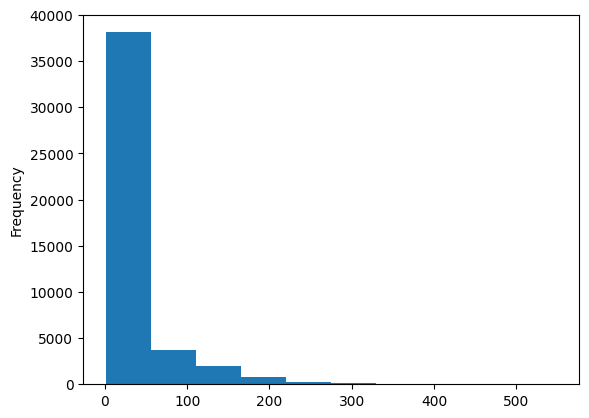

In [42]:
engineered_features['days_to_process'].plot(kind='hist')

In [43]:
engineered_features['touches_per_day'] = engineered_features['audit_count'] / engineered_features['days_to_process']

In [38]:
# Replace inf values with 0.1
engineered_features['touches_per_day'].replace(np.inf, -99, inplace=True)

In [45]:
engineered_features['touches_per_day']

0        0.318182
1        5.000000
2        0.446154
3        0.189189
4        0.175676
           ...   
45001    4.000000
45002    4.000000
45003    4.000000
45004    4.000000
45005    4.000000
Name: touches_per_day, Length: 45006, dtype: float64

<Axes: ylabel='Frequency'>

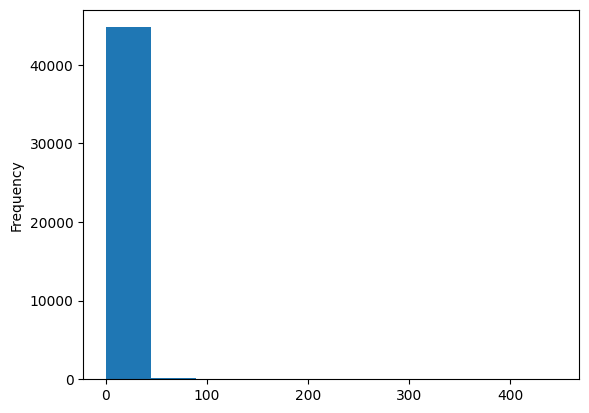

In [46]:
engineered_features['touches_per_day'].plot(kind='hist')

In [80]:
engineered_features

,sample_number,audit_count,last_audit_date,first_audit_date,days_to_process,touches_per_day
0,5824,14,2021-08-11 20:25:50,2021-06-28 12:56:59,44,0.318182
1,5812,5,2021-06-29 16:10:27,2021-06-28 12:56:59,1,5.000000
2,5876,29,2021-09-01 15:48:25,2021-06-28 12:49:45,65,0.446154
3,5877,14,2021-09-10 15:26:21,2021-06-28 12:53:10,74,0.189189
4,5884,13,2021-09-10 15:26:21,2021-06-28 12:53:14,74,0.175676
...,...,...,...,...,...,...
45001,48803,4,2023-12-04 05:02:36,2023-12-04 05:02:36,1,4.000000
45002,48806,4,2023-12-04 05:02:37,2023-12-04 05:02:37,1,4.000000
45003,48807,4,2023-12-04 05:02:38,2023-12-04 05:02:38,1,4.000000
45004,48814,4,2023-12-04 05:02:41,2023-12-04 05:02:41,1,4.000000


In [83]:
mod_dat = dat[['sample_number','audit_action','audit_timestamp','audit_type','audit_counter','trans_order','table_name','record_signed','user_role']]

In [84]:
mod_dat = pd.merge(mod_dat,engineered_features, on='sample_number')

In [111]:
mod_dat['seconds_since_start'] = (mod_dat['audit_timestamp'] - mod_dat['first_audit_date']).dt.total_seconds()

In [112]:
fieldDictUnsupervised = ['audit_action','audit_timestamp','audit_type','audit_counter','trans_order','table_name','record_signed','user_role','audit_count','days_to_process','touches_per_day', 'seconds_since_start']

unsupervisedH2oFrame = h2o.H2OFrame(python_obj=mod_dat)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [93]:
from h2o.estimators import H2OIsolationForestEstimator

In [113]:
isolation_model = H2OIsolationForestEstimator(model_id = "isolation_forest.hex", seed = 1234)
isolation_model.train(training_frame = unsupervisedH2oFrame, x = fieldDictUnsupervised)

isolationforest Model Build progress: |

██████████████████████████████████████████| (done) 100%


Model Details
=============
H2OIsolationForestEstimator : Isolation Forest
Model Key: isolation_forest.hex


Model Summary: 
    number_of_trees    number_of_internal_trees    model_size_in_bytes    min_depth    max_depth    mean_depth    min_leaves    max_leaves    mean_leaves
--  -----------------  --------------------------  ---------------------  -----------  -----------  ------------  ------------  ------------  -------------
    50                 50                          37187                  5            8            7.94          6             105           54.34

ModelMetricsAnomaly: isolationforest
** Reported on train data. **

Anomaly Score: 6.237555327495982
Normalized Anomaly Score: 0.15561116812600226

Scoring History: 
     timestamp            duration    number_of_trees    mean_tree_path_length    mean_anomaly_score
---  -------------------  ----------  -----------------  -----------------------  --------------------
     2024-01-26 14:17:35  0.077 sec   0.0                nan                      nan
     2024-01-26 14:17:35  0.394 sec   1.0                5.772840563311366        0.24543188733774005
     2024-01-26 14:17:35  0.603 sec   2.0                6.001465250448936        0.249633687387766
     2024-01-26 14:17:36  0.837 sec   3.0                6.220103096065946        0.19497422598351888
     2024-01-26 14:17:36  1.013 sec   4.0                6.309412053133636        0.1624912816155999
     2024-01-26 14:17:36  1.250 sec   5.0                5.068069908582065        0.3171262122423151
     2024-01-26 14:17:36  1.723 sec   6.0                5.37003957333181         0.19119050240037658
     2024-01-26 14:17:37  1.931 sec   7.0                5.537112543812574        0.19408193308561697
     2024-01-26 14:17:37  2.085 sec   8.0                5.698618720828532        0.15914853627562547
     2024-01-26 14:17:37  2.243 sec   9.0                5.796307795382175        0.14227389857459047
---  ---                  ---         ---                ---                      ---
     2024-01-26 14:17:38  2.822 sec   13.0               6.039026659734383        0.10363497025375802
     2024-01-26 14:17:38  2.944 sec   14.0               6.072292753222399        0.10323968025667245
     2024-01-26 14:17:38  3.130 sec   15.0               6.104619826583921        0.10717837668732287
     2024-01-26 14:17:38  3.286 sec   16.0               6.116614567281184        0.11695355612296884
     2024-01-26 14:17:38  3.421 sec   17.0               6.132051966024489        0.11930948580906207
     2024-01-26 14:17:38  3.557 sec   18.0               6.162016496491908        0.11715511685720216
     2024-01-26 14:17:38  3.697 sec   19.0               6.173320316952543        0.1261871591000106
     2024-01-26 14:17:39  3.819 sec   20.0               5.929492796191813        0.18960715889690138
     2024-01-26 14:17:39  4.082 sec   21.0               5.92898411673432         0.19125103146390834
     2024-01-26 14:17:43  8.224 sec   50.0               6.237555327495982        0.15561116812600226
[23 rows x 6 columns]


[tips]
Use `model.explain()` to inspect the model.
--
Use `h2o.display.toggle_user_tips()` to switch on/off this section.

In [114]:
predictions = isolation_model.predict(unsupervisedH2oFrame)
predictions.head()

isolationforest prediction progress: |

███████████████████████████████████████████| (done) 100%


predict,mean_length
0.285,5.72
0.28,5.74
0.26,5.82
0.24,5.9
0.225,5.96
0.185,6.12
0.18,6.14
0.19,6.1
0.18,6.14
0.16,6.22


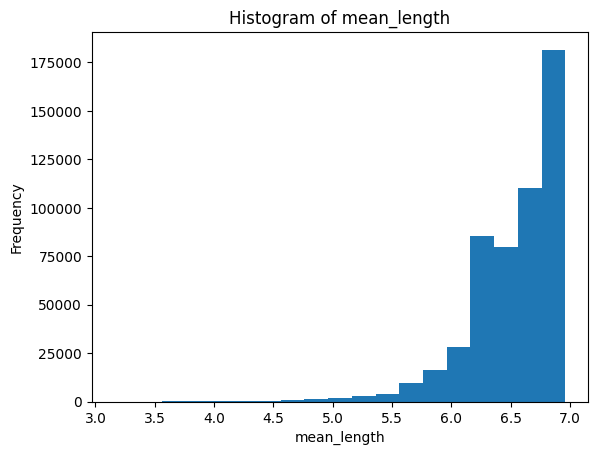

breaks,counts,mids_true,mids,widths
3.06,nan,nan,nan,nan
3.26,4,1.43,3.16,0.2
3.46,40,1.54,3.36,0.2
3.66,54,1.64,3.56,0.2
3.86,96,1.73,3.76,0.2
4.06,111,1.83,3.96,0.2
4.26,314,1.93,4.16,0.2
4.46,516,2.04,4.36,0.2
4.66,860,2.14,4.56,0.2
4.86,1569,2.23,4.76,0.2


In [125]:
predictions["mean_length"].hist()

In [117]:
anomalies = unsupervisedH2oFrame[predictions["mean_length"] < 5.0]
print("Number of Anomalies: " + str(anomalies.nrow))

Number of Anomalies: 7327


In [ ]:
missing_percentages = dat.isnull().mean() * 100

In [56]:
total_columns = len(missing_percentages)
high_missing = (missing_percentages > 5)==True

In [59]:
fields_missing_more_than_50_percent = (missing_percentages > 50).sum()


In [62]:
print('A total of ' + str(fields_missing_more_than_50_percent) + ' of the ' + str(total_columns) + ' are missing more than 50 percent of values')

A total of 216 of the 249 are missing more than 50 percent of values


In [63]:
print(dat.columns.values)

['audit_table_name' 'audit_action' 'audit_timestamp' 'audit_type'
 'audit_counter' 'trans_order' 'table_name' 'table_key' 'reason'
 'record_signed' 'user_name' 'user_role' 'parent_table' 'parent_key'
 'batch_name' 'col_num' 'document_number' 'experiment_number' 'row_num'
 'workbook_number' 'worksheet' 'formulation' 'investigation' 'order_num'
 'project_name' 'name' 'report_number' 'sample_number' 'location_number'
 't_mlar' 't_mlar_severity' 'SAMPLE_NUMBER_norm' 'TEST_NUMBER_norm'
 'RESULT_NUMBER_norm' 'ORDER_NUMBER_norm' 'ANALYSIS_norm' 'NAME_norm'
 'REPORTED_NAME_norm' 'REPLICATE_COUNT_norm' 'RESULT_TYPE_norm'
 'STATUS_norm' 'OLD_STATUS_norm' 'MODIFIED_RESULT_norm' 'ALLOW_OUT_norm'
 'UNITS_norm' 'ROUND_norm' 'PLACES_norm' 'IN_SPEC_norm'
 'PRIMARY_IN_SPEC_norm' 'USES_INSTRUMENT_norm' 'USES_CODES_norm'
 'IN_CAL_norm' 'AUTO_CALC_norm' 'ALLOW_CANCEL_norm' 'LINK_SIZE_norm'
 'REPORTABLE_norm' 'OPTIONAL_norm' 'CODE_ENTERED_norm' 'CHANGED_ON_norm'
 'STD_REAG_SAMPLE_norm' 'HAS_ATTRIBUTES_norm

In [69]:
missing_percentages = missing_percentages.reset_index


In [79]:
dat['batch_name'].value_counts()

batch_name
    523460
Name: count, dtype: int64

In [121]:
global_surrogate_data = unsupervisedH2oFrame[:, :]
global_surrogate_data["anomaly"] = (predictions["mean_length"] < 5.0).ifelse("Yes", "No")
global_surrogate_data["anomaly"].table()

anomaly,Count
No,516133
Yes,7327


In [123]:
from h2o.estimators import H2ORandomForestEstimator

global_surrogate_dt = H2ORandomForestEstimator(model_id = "global_surrogate_decision_tree.hex", 
                                               ntrees = 1, max_depth = 3,
                                               sample_rate = 1, mtries = -1)
global_surrogate_dt.train(training_frame = global_surrogate_data, x = fieldDictUnsupervised, y = "anomaly")

drf Model Build progress: |██████████████████████████████████████████████████████| (done) 100%


Model Details
=============
H2ORandomForestEstimator : Distributed Random Forest
Model Key: global_surrogate_decision_tree.hex


Model Summary: 
    number_of_trees    number_of_internal_trees    model_size_in_bytes    min_depth    max_depth    mean_depth    min_leaves    max_leaves    mean_leaves
--  -----------------  --------------------------  ---------------------  -----------  -----------  ------------  ------------  ------------  -------------
    1                  1                           158                    3            3            3             8             8             8

ModelMetricsBinomial: drf
** Reported on train data. **

MSE: NaN
RMSE: NaN
LogLoss: NaN
Mean Per-Class Error: NaN
AUC: NaN
AUCPR: NaN
Gini: NaN

Scoring History: 
    timestamp            duration    number_of_trees    training_rmse    training_logloss    training_auc    training_pr_auc    training_lift    training_classification_error
--  -------------------  ----------  -----------------  ---------------  ------------------  --------------  -----------------  ---------------  -------------------------------
    2024-01-26 14:22:04  0.492 sec   0                  nan              nan                 nan             nan                nan              nan

Variable Importances: 
variable         relative_importance    scaled_importance    percentage
---------------  ---------------------  -------------------  ------------
trans_order      4224.72                1                    0.921506
touches_per_day  154.111                0.0364785            0.0336152
audit_count      120.572                0.0285396            0.0262994
audit_type       84.2013                0.0199306            0.0183662
audit_timestamp  0.97644                0.000231126          0.000212984
audit_action     0                      0                    0
audit_counter    0                      0                    0
table_name       0                      0                    0
record_signed    0                      0                    0
user_role        0                      0                    0
days_to_process  0                      0                    0

[tips]
Use `model.explain()` to inspect the model.
--
Use `h2o.display.toggle_user_tips()` to switch on/off this section.

In [103]:
import os
import subprocess
from IPython.display import Image
def generateTreeImage(decision_tree, image_file_path):
    # Download MOJO
    mojo_path = decision_tree.download_mojo(get_genmodel_jar=True)
    directory = os.path.dirname(mojo_path)
    h2o_jar_path = os.path.join(directory, "h2o-genmodel.jar")
    # Create Graphviz file
    gv_file_path = os.path.join(directory, "decision_tree.gv")
    gv_call = " ".join(["java", "-cp", h2o_jar_path, "hex.genmodel.tools.PrintMojo", "--tree 0 -i", mojo_path , "-o", gv_file_path])
    result = subprocess.call(gv_call, shell=True)
    result = subprocess.call(["dir", gv_file_path], shell = False)
    result = subprocess.call(["dot", "-Tpng", gv_file_path, "-o", image_file_path], shell=False)
    result = subprocess.call(["dir",image_file_path], shell = False)
    
    return Image(image_file_path)

# Confusion Matrix

> Confusion matrix shows a predicted class vs an actual class.

## global_surrogate_decision_tree.hex

,No,Yes,Error,Rate
No,515160.0,973.0,0.0019,(973.0/516133.0)
Yes,2038.0,5289.0,0.2781,(2038.0/7327.0)
Total,517198.0,6262.0,0.0058,(3011.0/523460.0)


# Learning Curve Plot

> Learning curve plot shows the loss function/metric dependent on number of iterations or trees for tree-based algorithms. This plot can be useful for determining whether the model overfits.

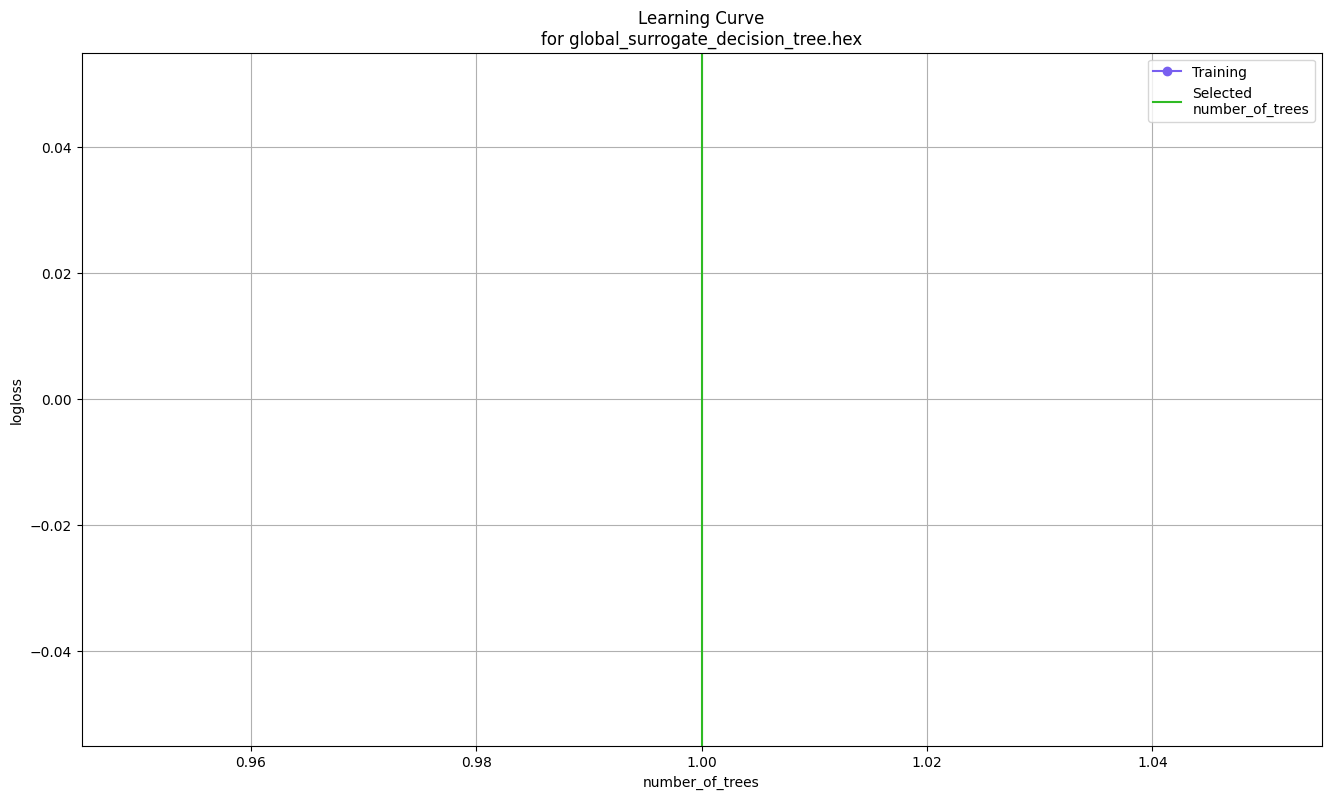

# Variable Importance

> The variable importance plot shows the relative importance of the most important variables in the model.

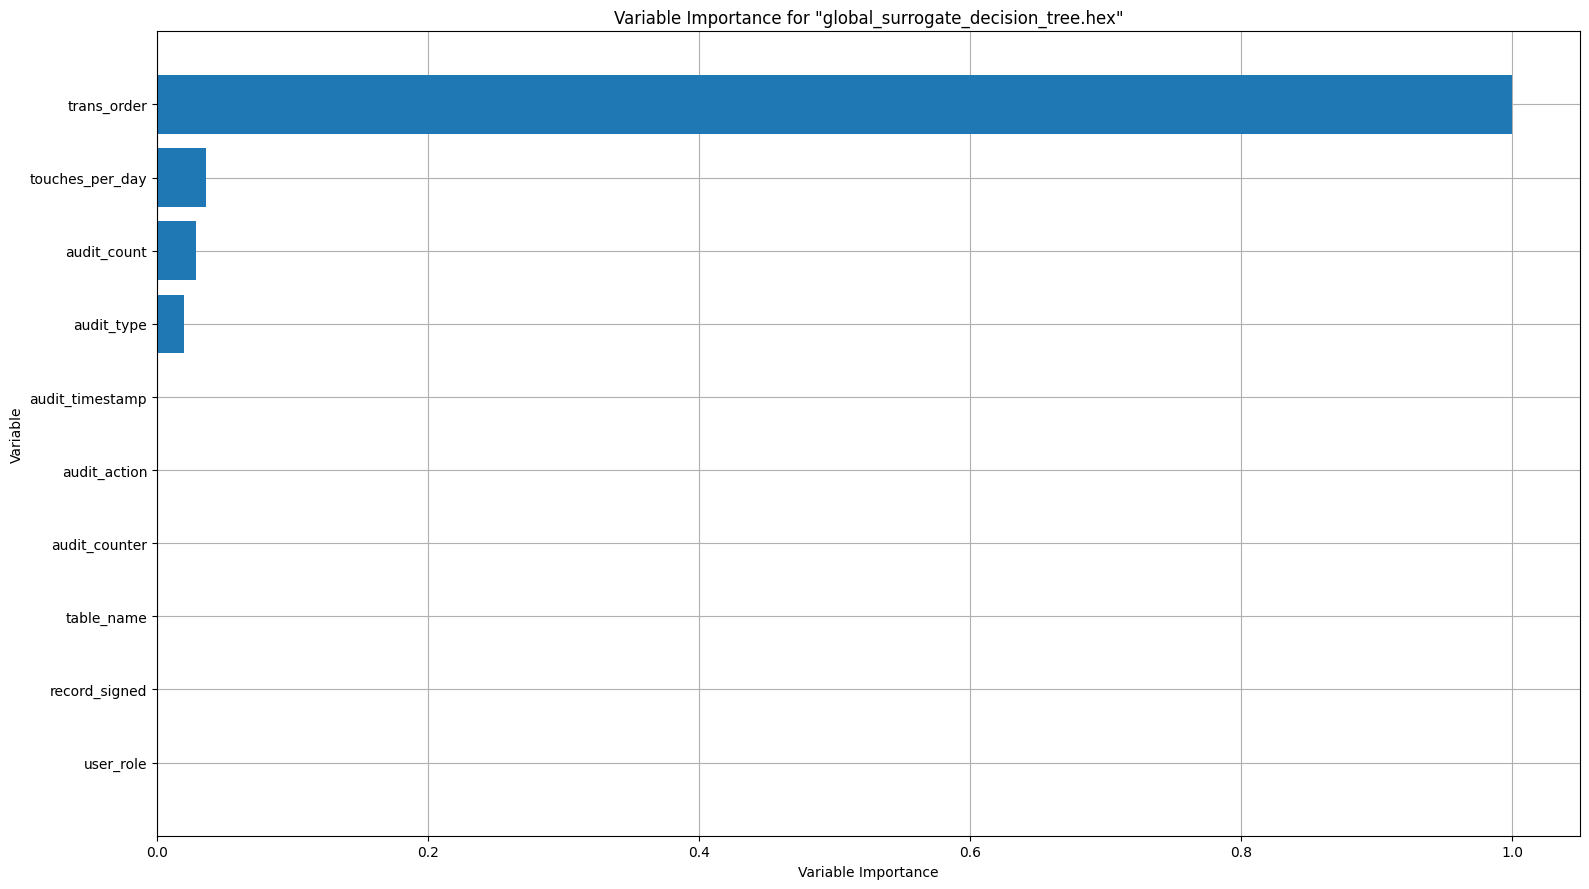

# SHAP Summary

> SHAP summary plot shows the contribution of the features for each instance (row of data). The sum of the feature contributions and the bias term is equal to the raw prediction of the model, i.e., prediction before applying inverse link function.

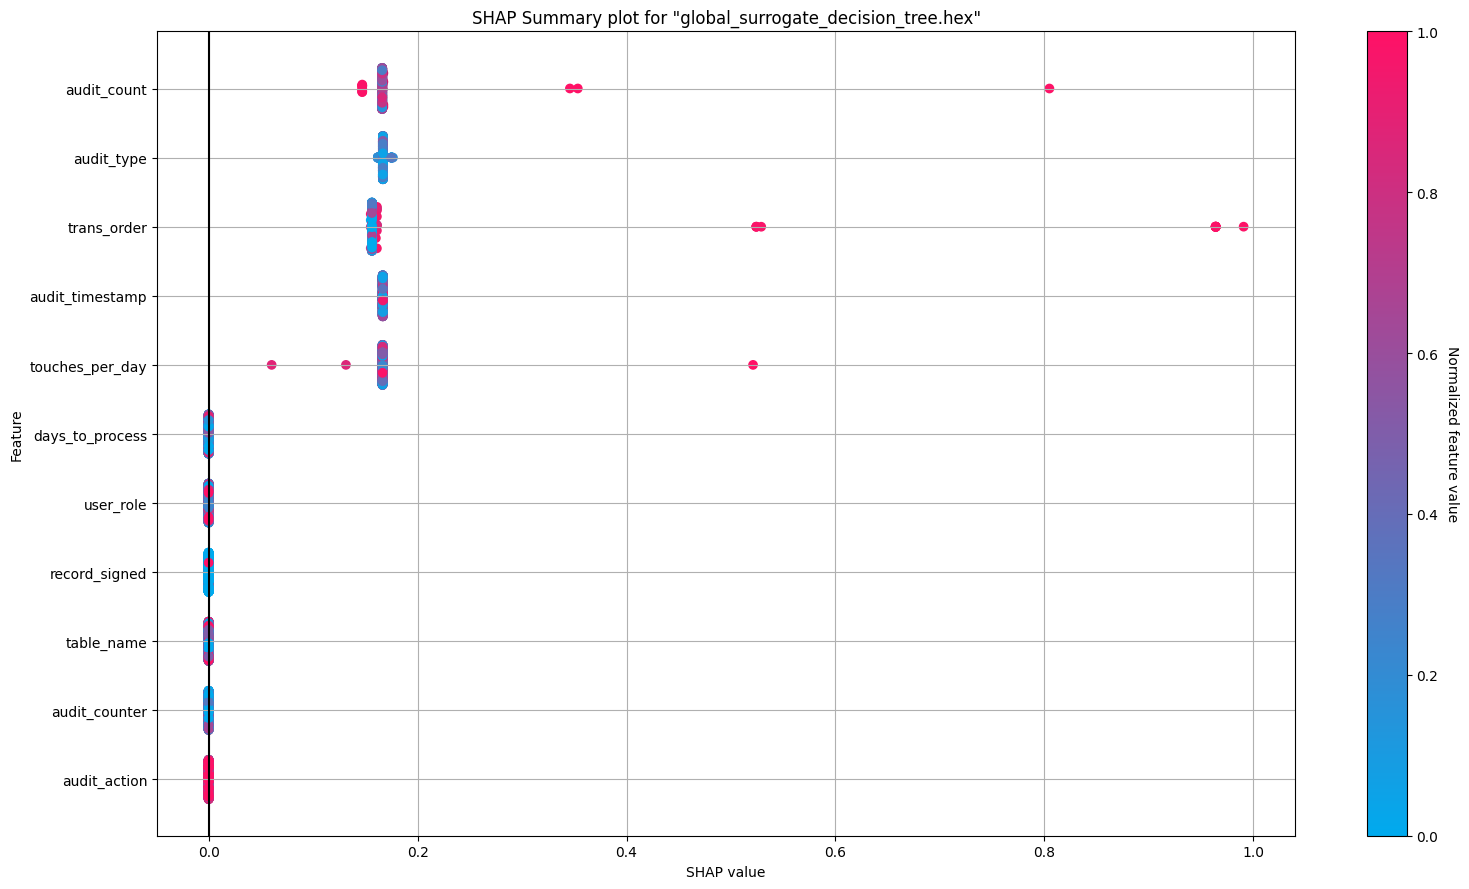

# Partial Dependence Plots

> Partial dependence plot (PDP) gives a graphical depiction of the marginal effect of a variable on the response. The effect of a variable is measured in change in the mean response. PDP assumes independence between the feature for which is the PDP computed and the rest.

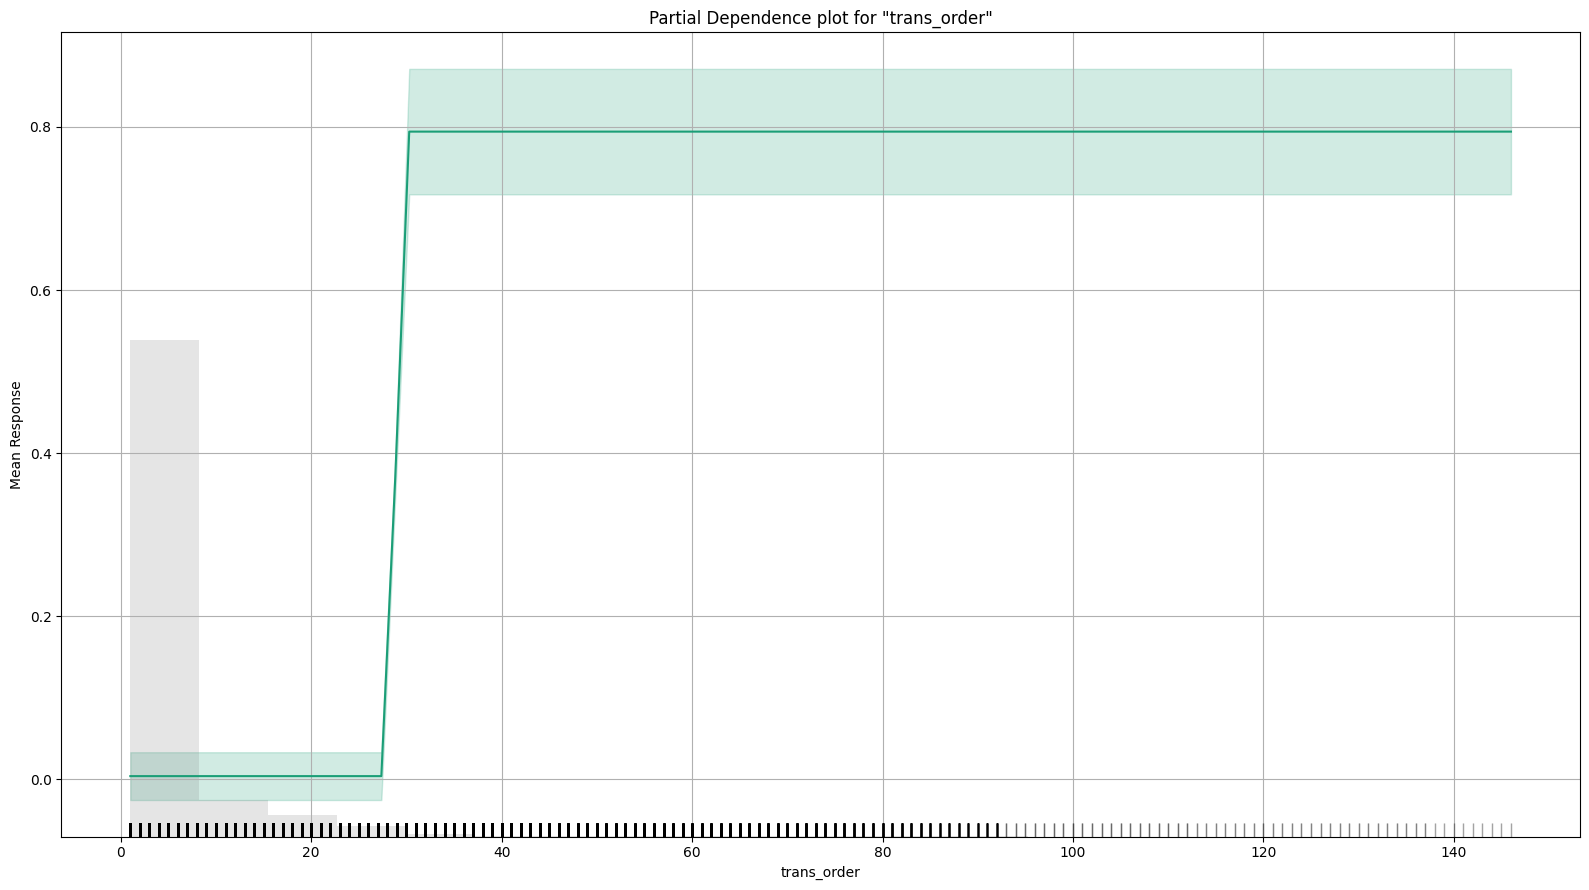

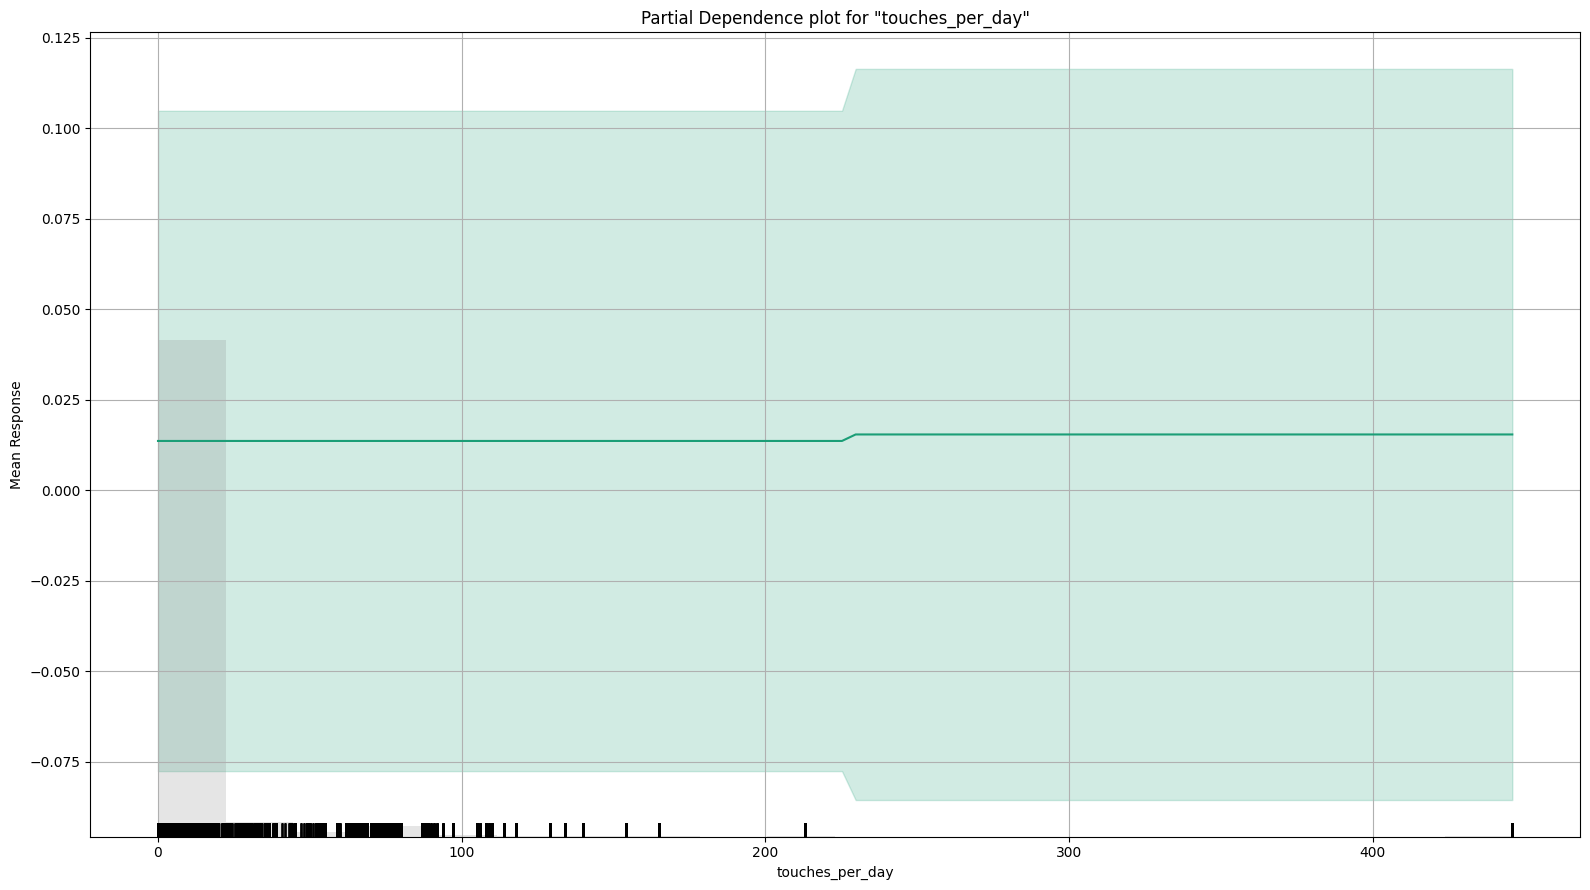

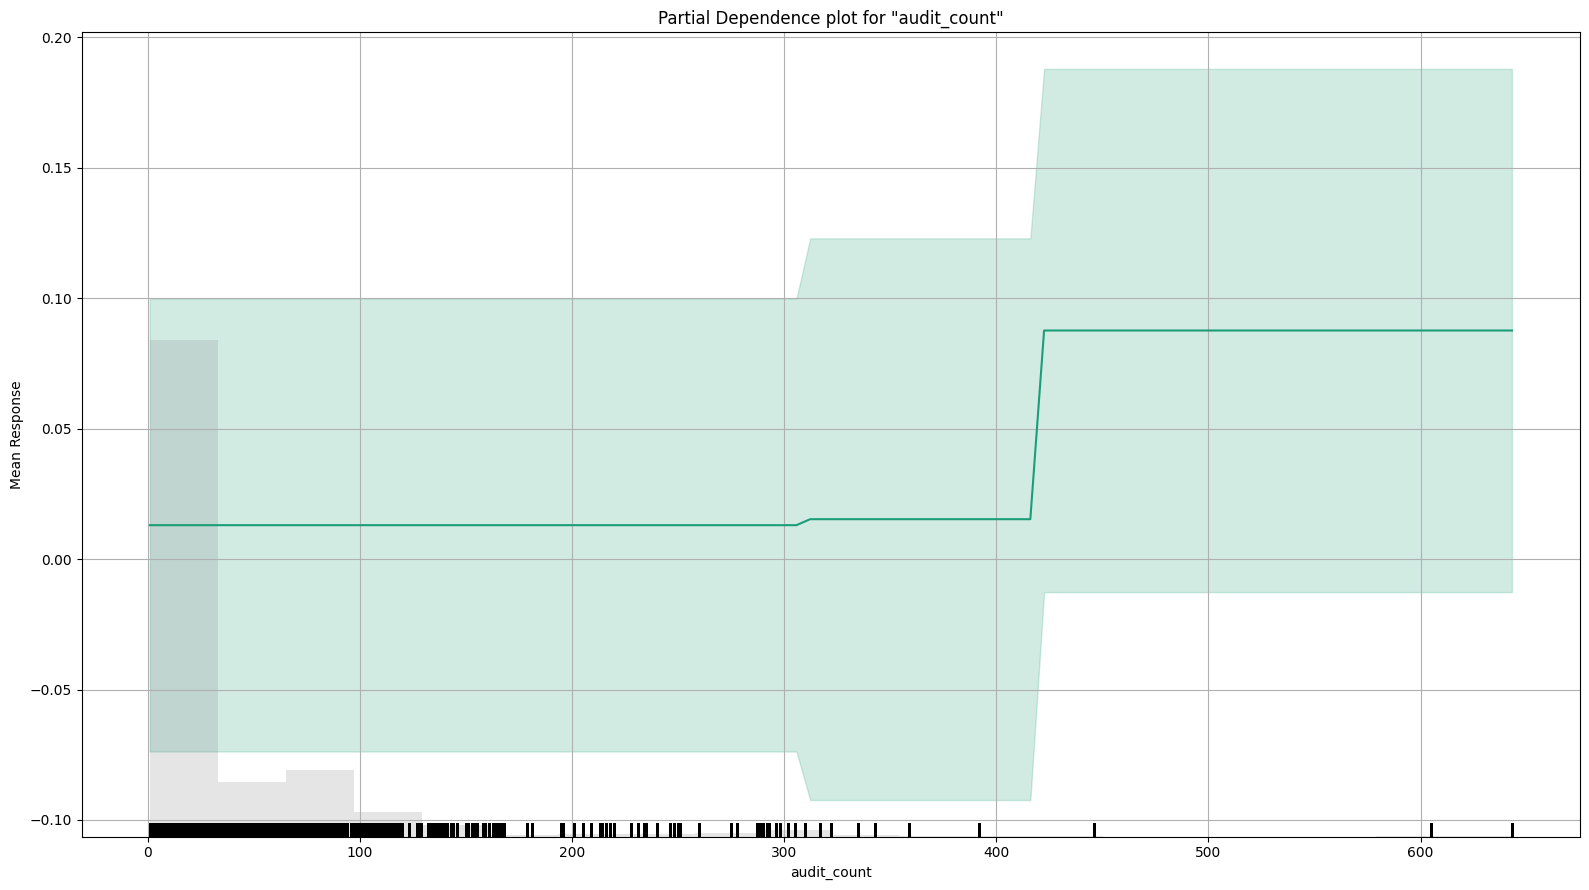

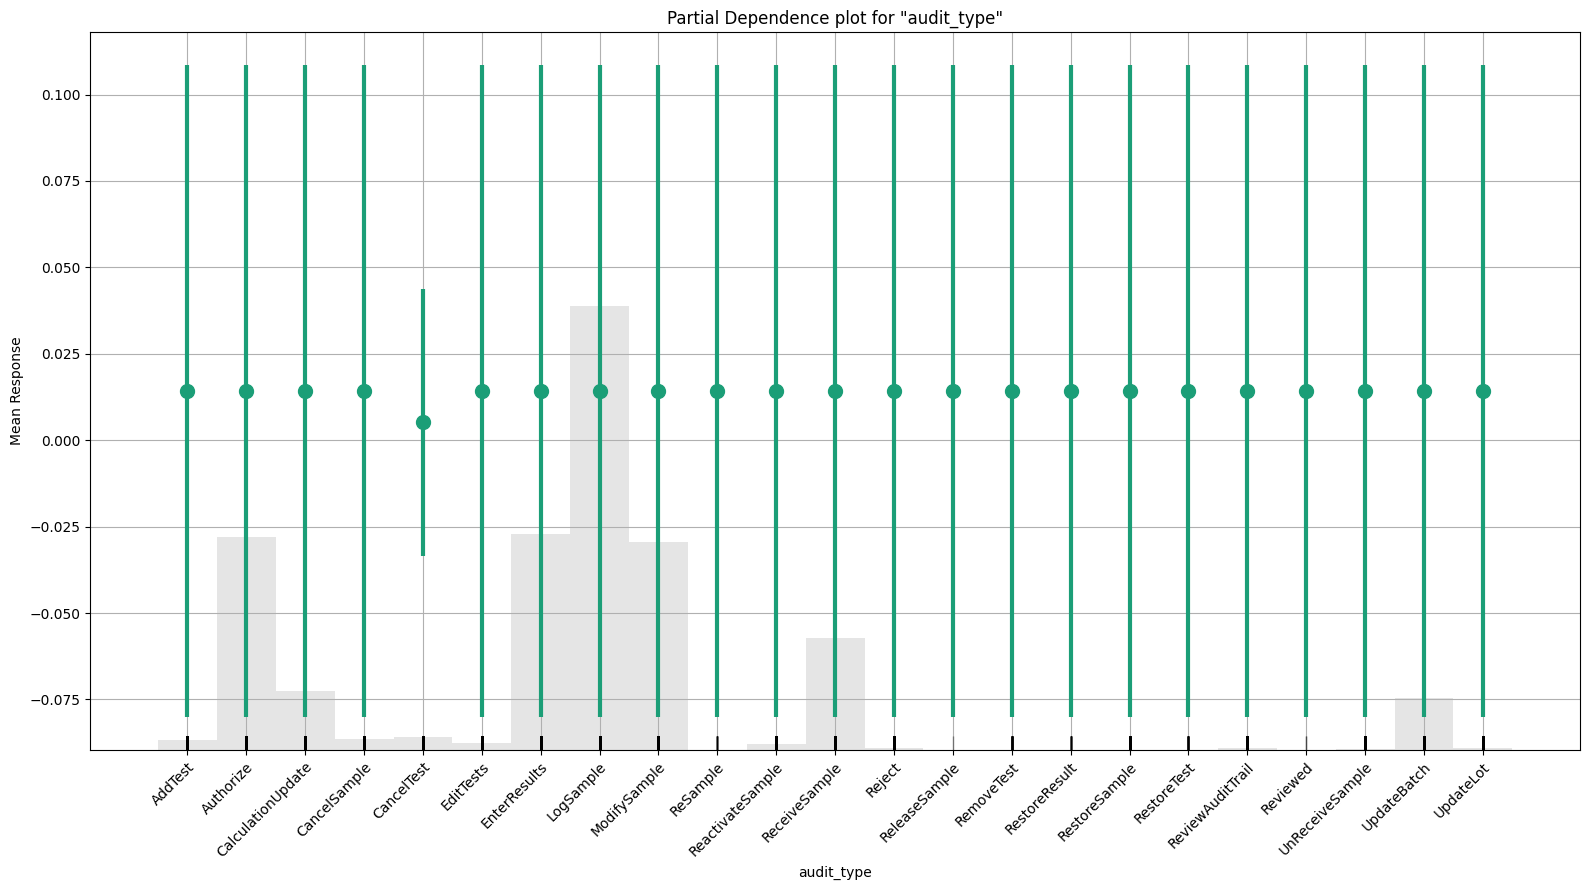

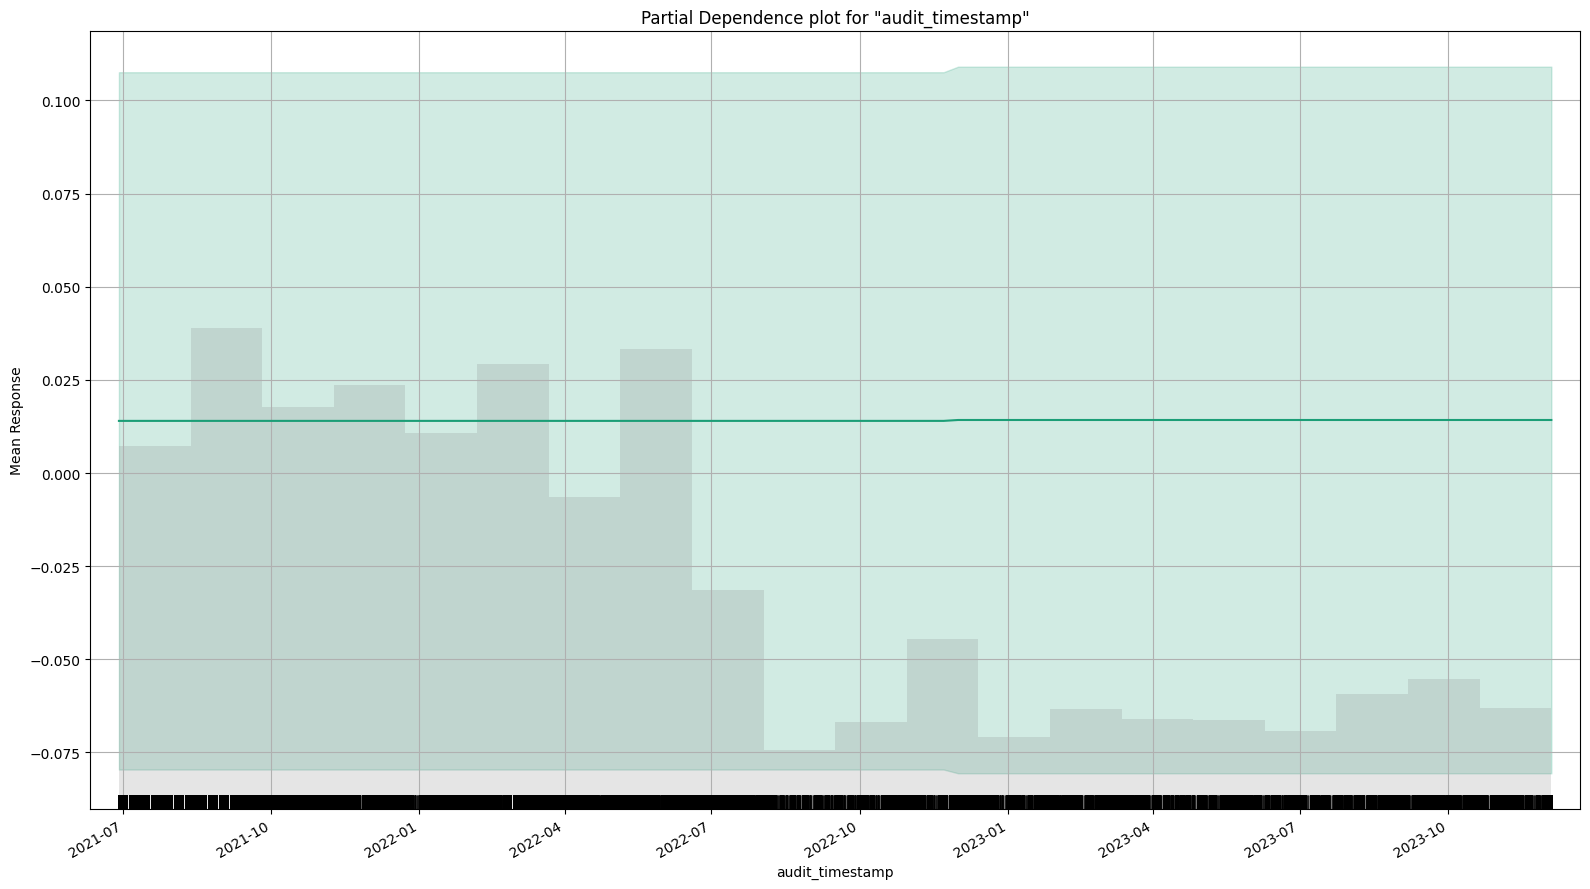

# Confusion Matrix

> Confusion matrix shows a predicted class vs an actual class.

## global_surrogate_decision_tree.hex

,No,Yes,Error,Rate
No,515160.0,973.0,0.0019,(973.0/516133.0)
Yes,2038.0,5289.0,0.2781,(2038.0/7327.0)
Total,517198.0,6262.0,0.0058,(3011.0/523460.0)


# Learning Curve Plot

> Learning curve plot shows the loss function/metric dependent on number of iterations or trees for tree-based algorithms. This plot can be useful for determining whether the model overfits.

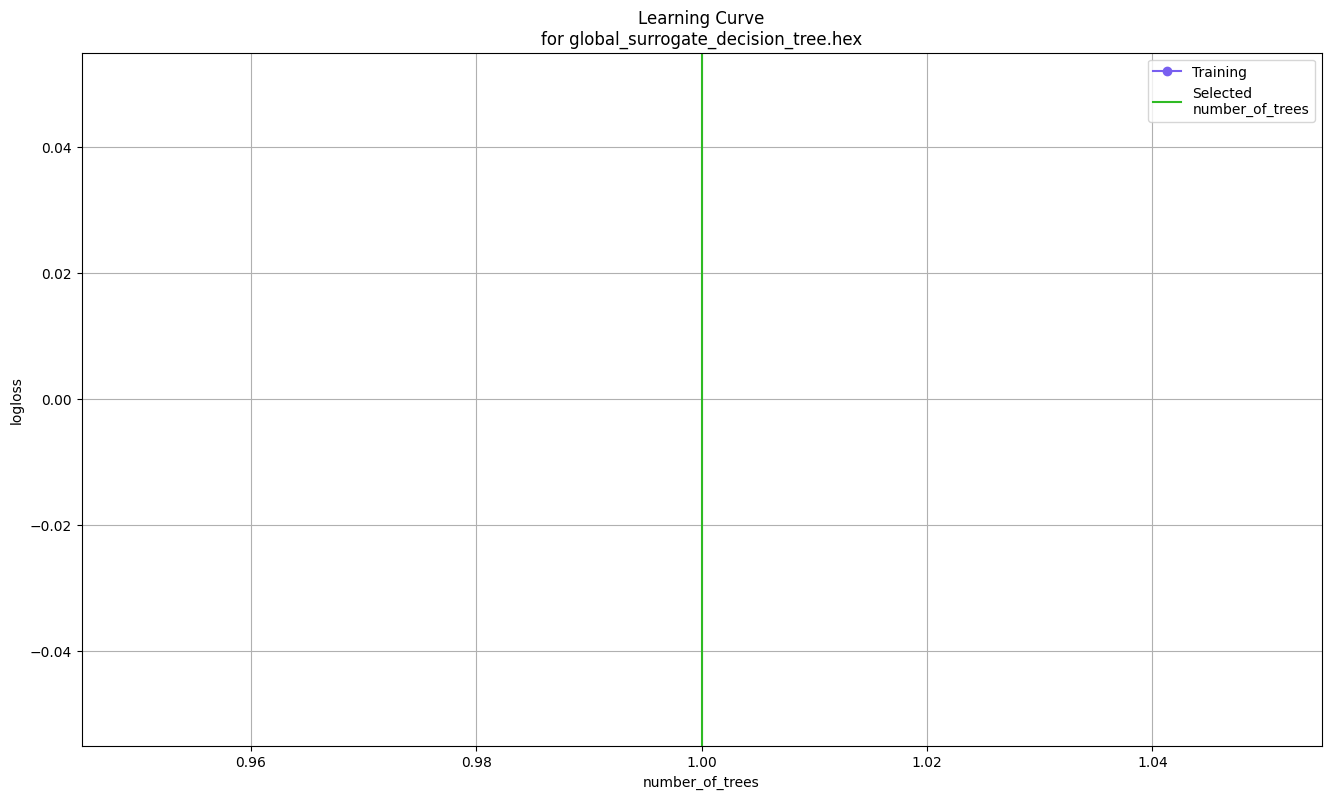

# Variable Importance

> The variable importance plot shows the relative importance of the most important variables in the model.

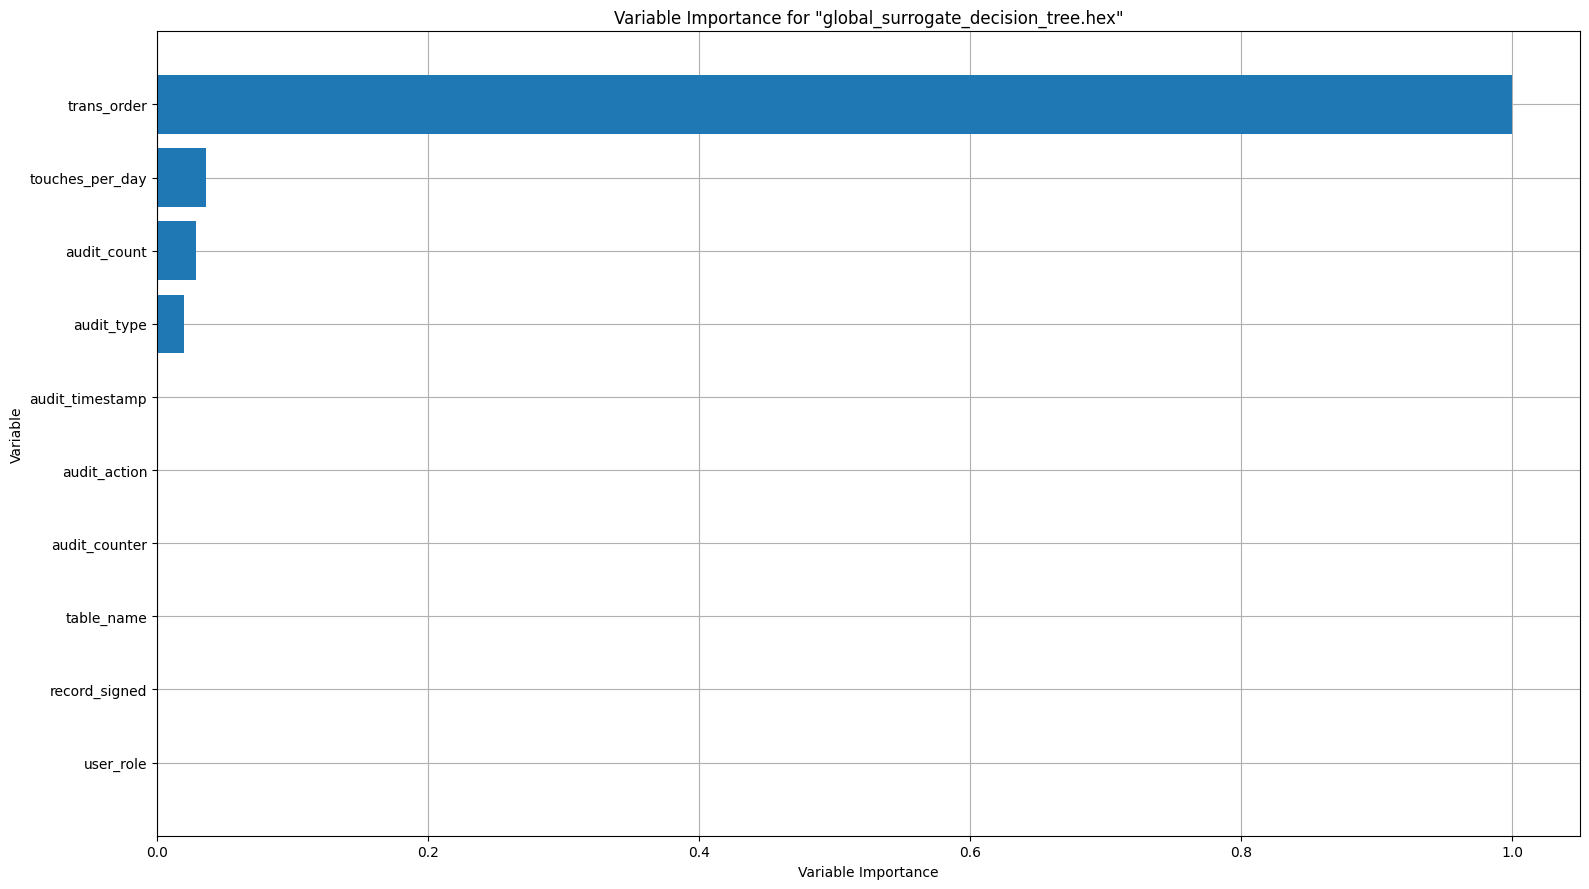

# SHAP Summary

> SHAP summary plot shows the contribution of the features for each instance (row of data). The sum of the feature contributions and the bias term is equal to the raw prediction of the model, i.e., prediction before applying inverse link function.

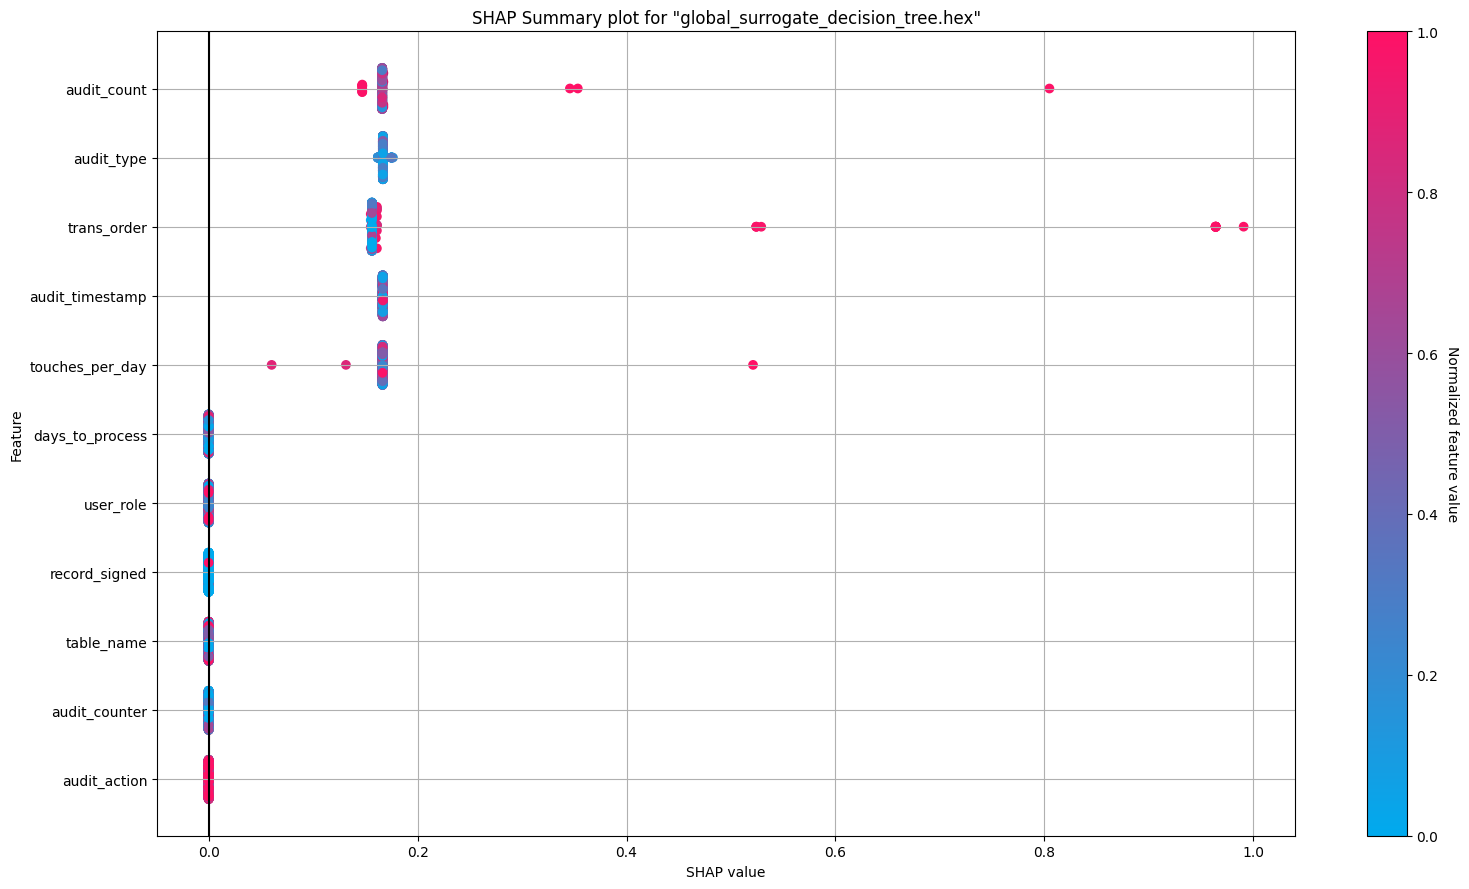

# Partial Dependence Plots

> Partial dependence plot (PDP) gives a graphical depiction of the marginal effect of a variable on the response. The effect of a variable is measured in change in the mean response. PDP assumes independence between the feature for which is the PDP computed and the rest.

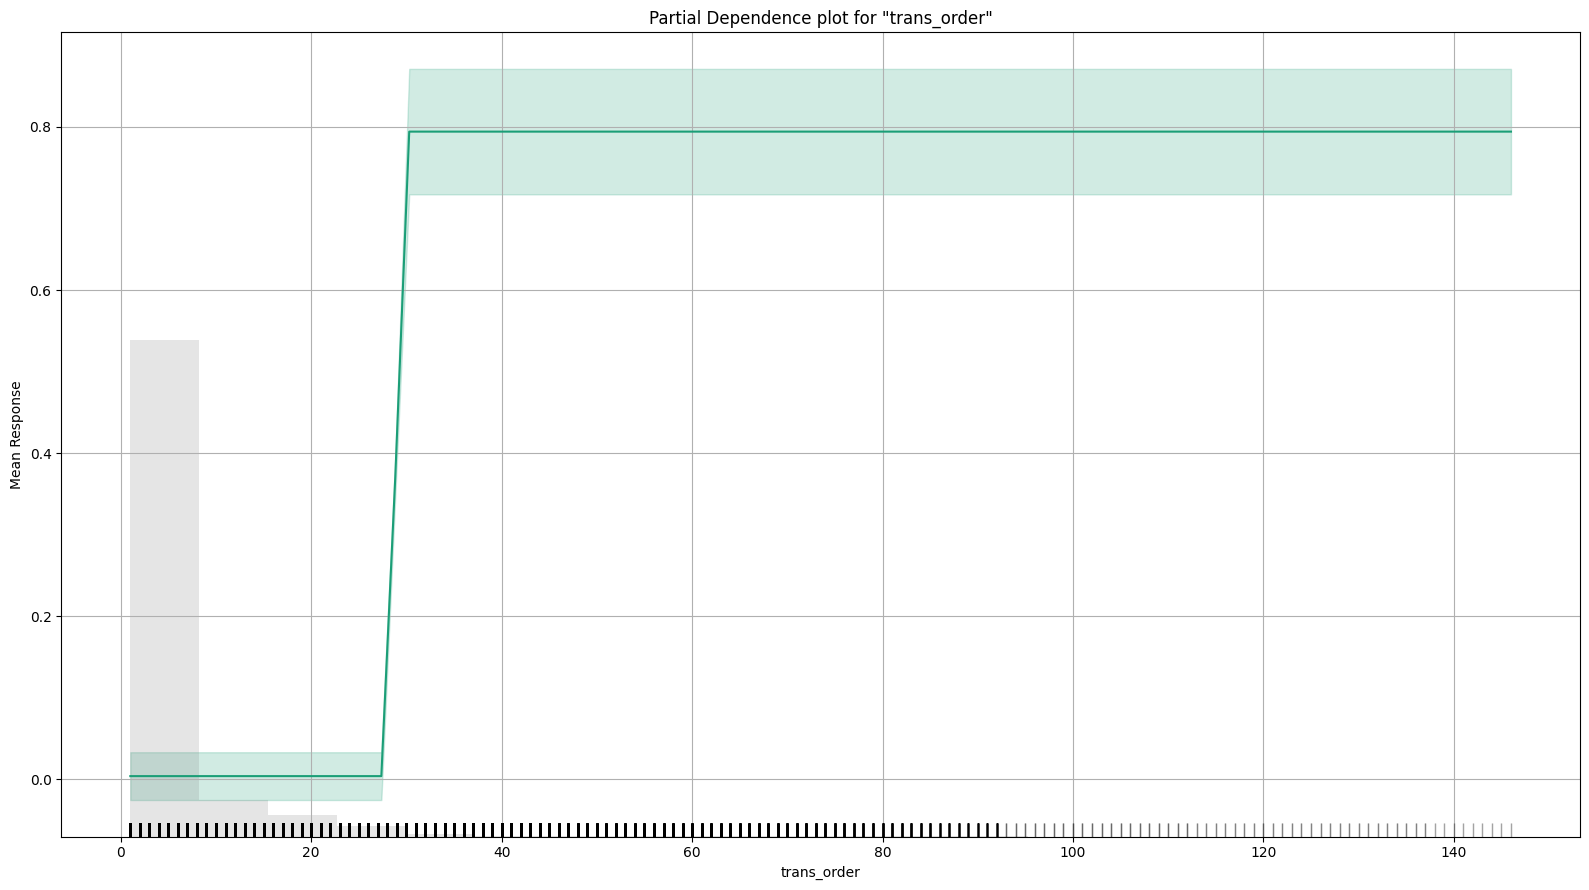

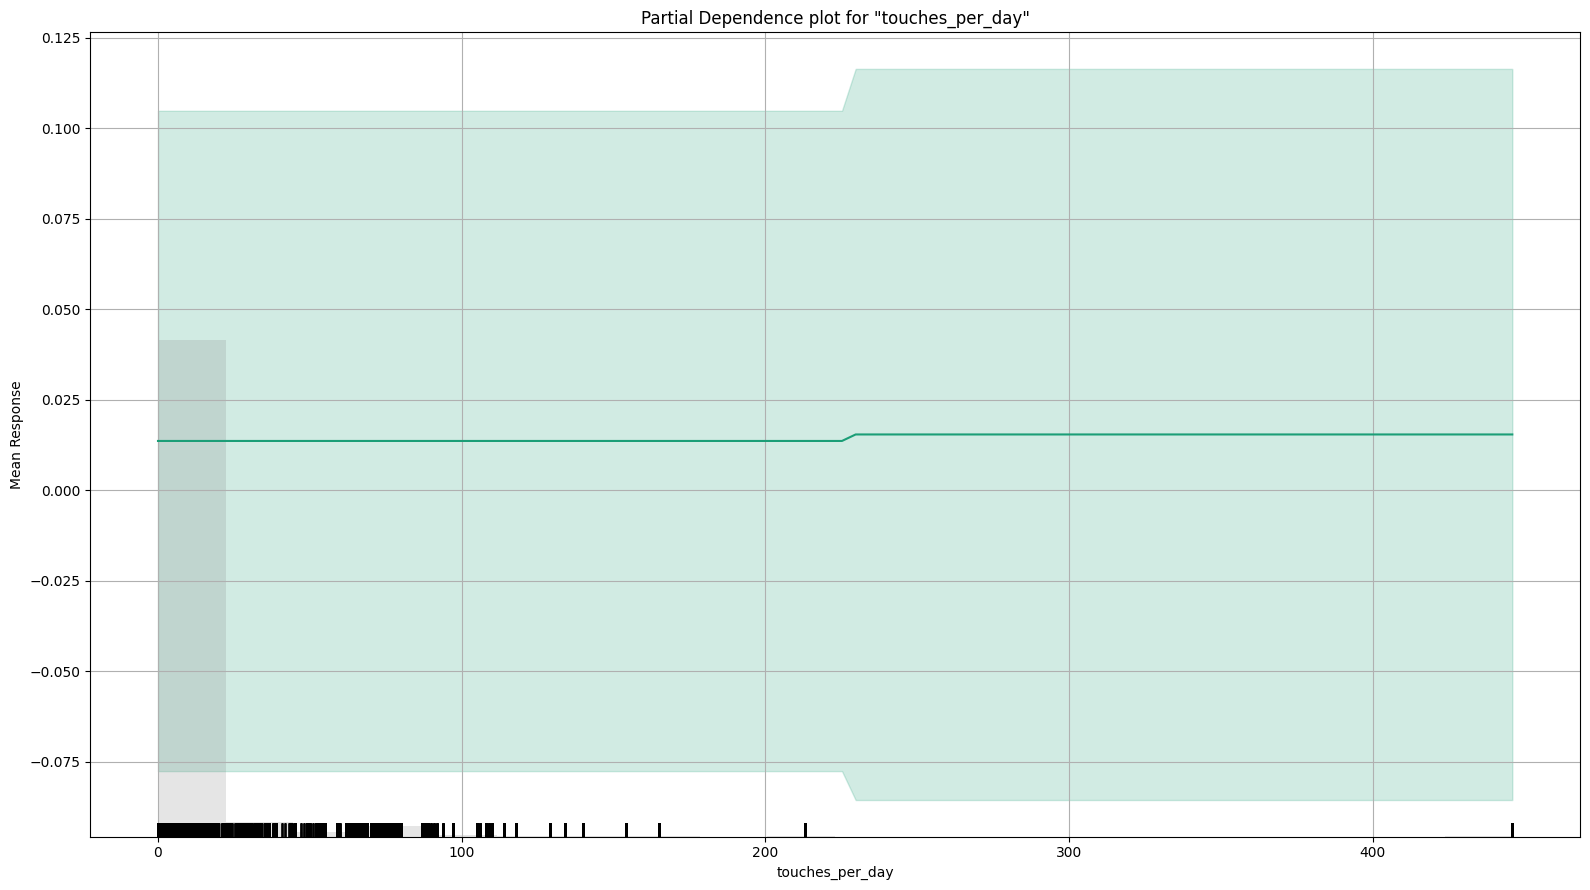

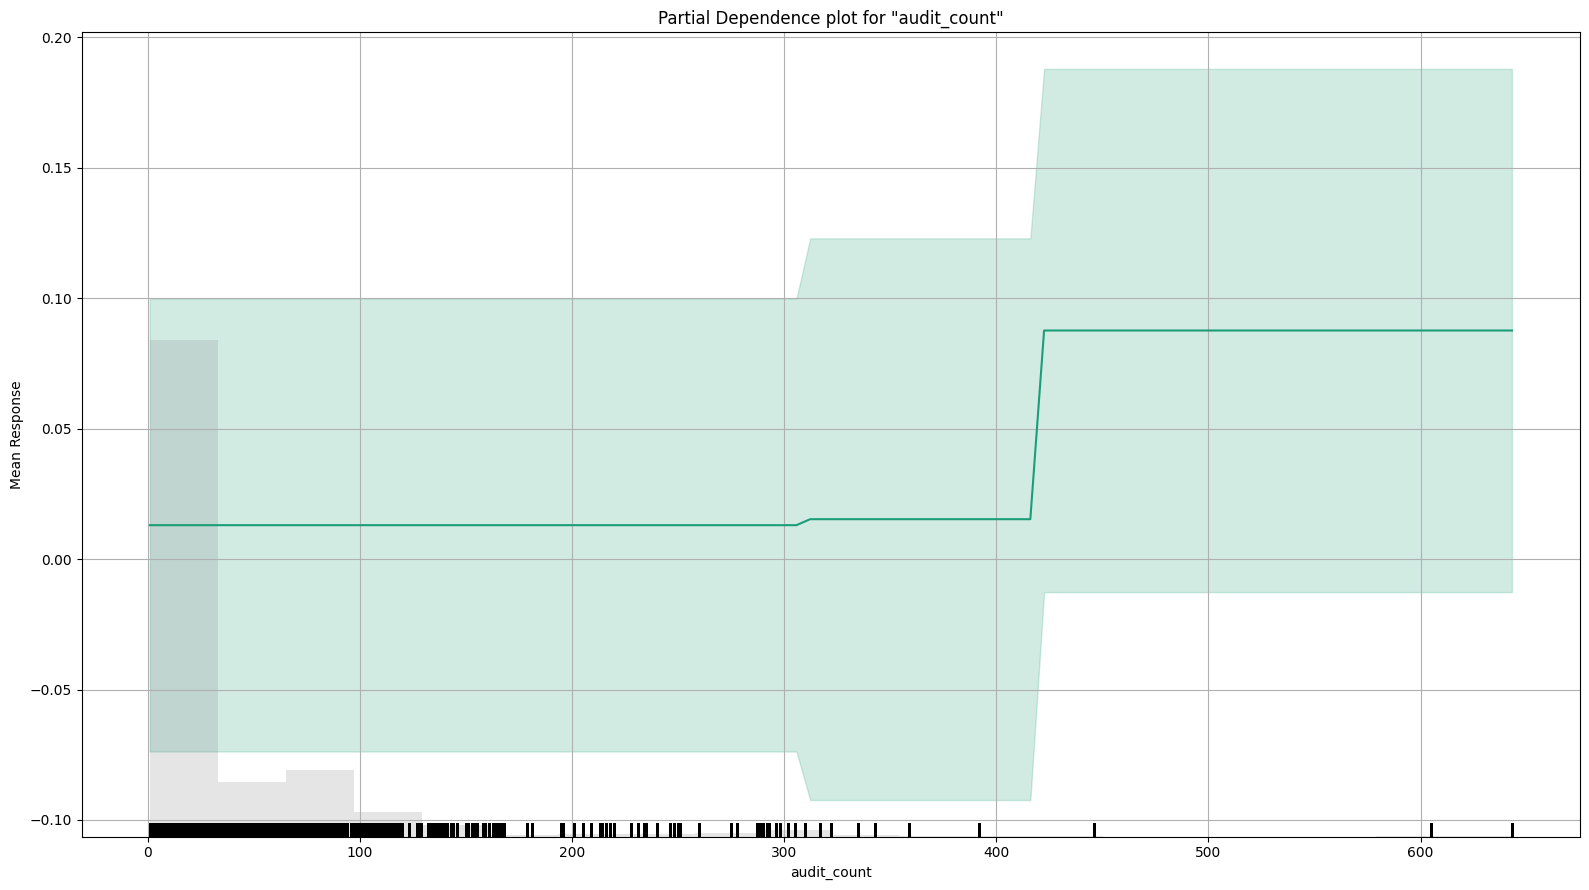

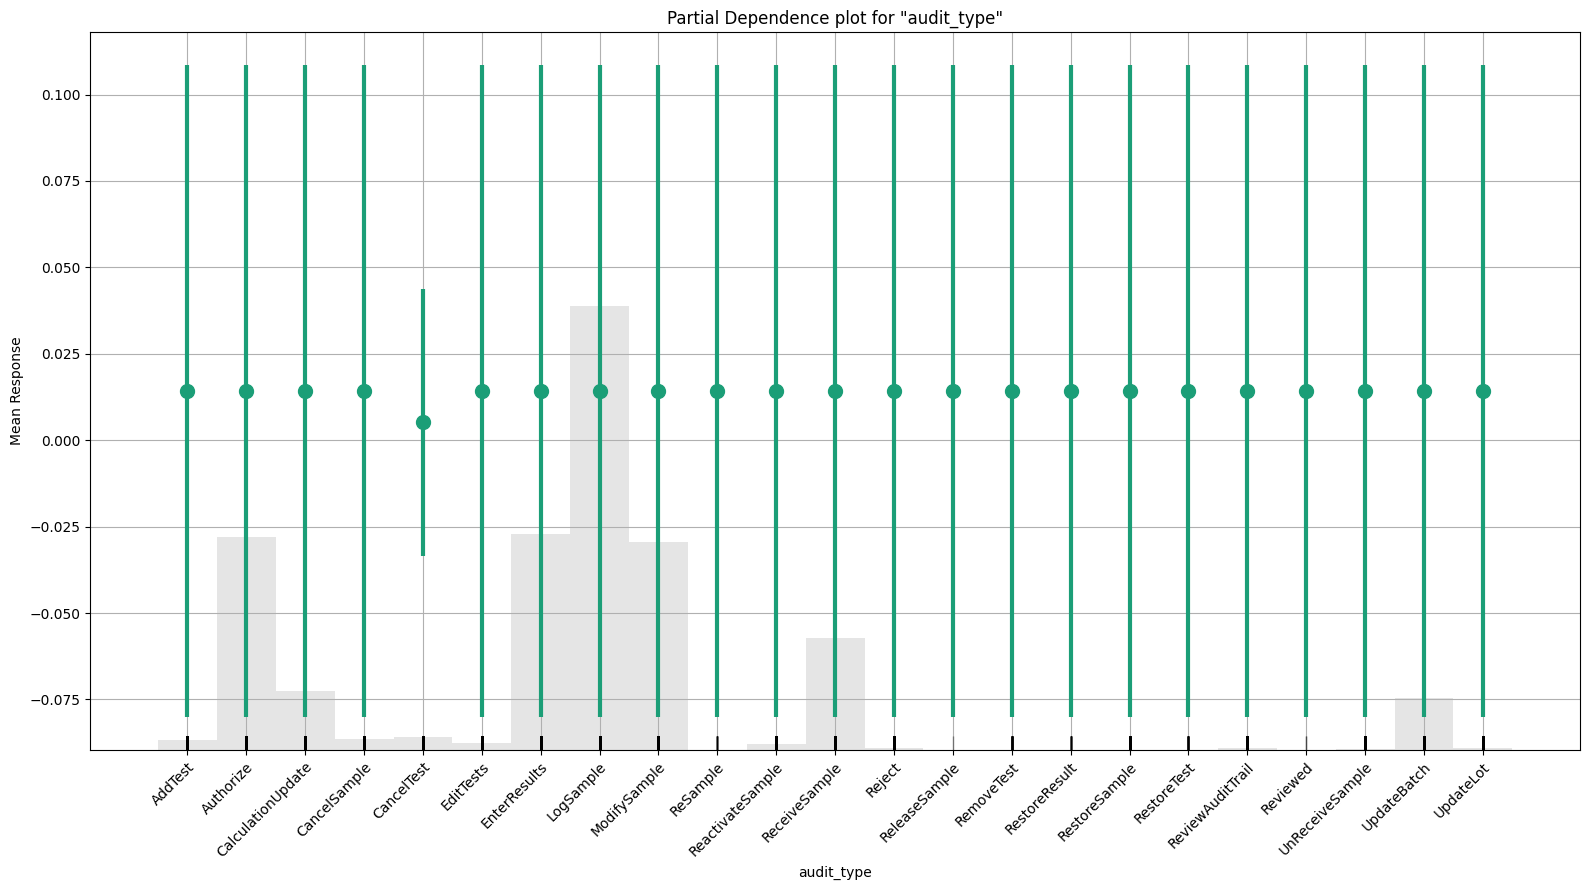

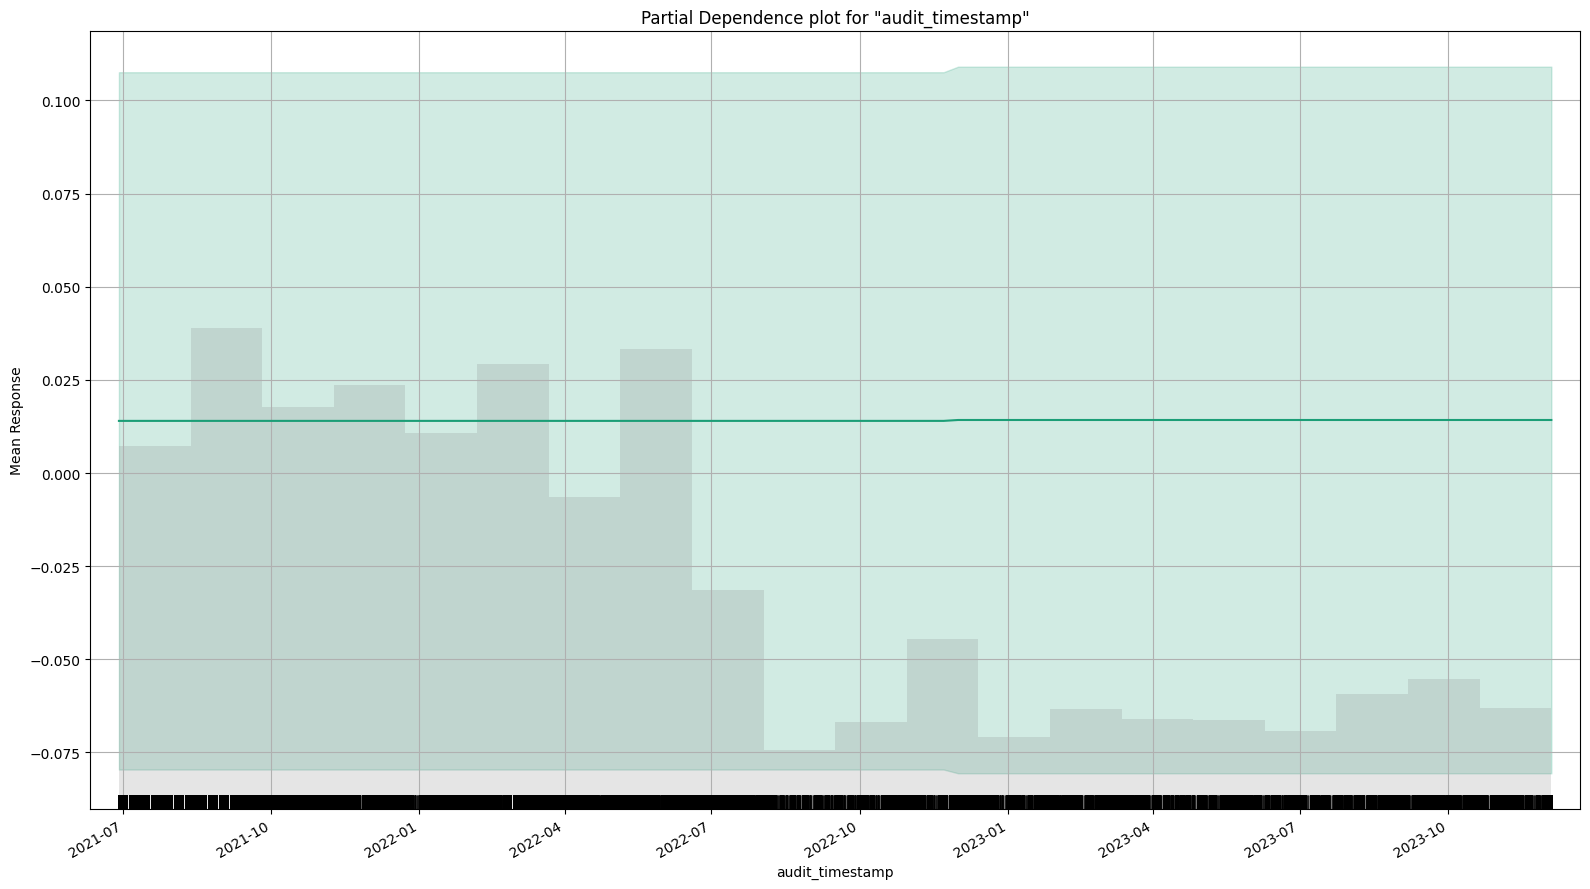

In [124]:
global_surrogate_dt.explain(unsupervisedH2oFrame)